# HOMEWORK 14

In this homework we will be working with the Fashion MNIST dataset. You will be given a classifier which suffers from considerable overfitting. Your objective will be to employ regularization techniques to mitigate the overfitting problem.

Let's start with the usual imports.

In [88]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D, BatchNormalization, RandomFlip
from tensorflow.keras import Model
from time import time
from tensorflow.keras import regularizers
from tensorflow import keras
from tensorflow.keras.layers import RandomTranslation, RandomZoom, RandomRotation

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seeds for reproducibility
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

# Check the number of available GPUs
gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs Available: ", len(gpus))

# Verify if built with CUDA support
print("Built with CUDA:", tf.test.is_built_with_cuda())

# Display detailed local device list
gpus = tf.config.list_physical_devices('GPU')
print(f"Number of GPUs available: {len(gpus)}")

for i, gpu in enumerate(gpus):
    # Details provide the device name / hardware info
    details = tf.config.experimental.get_device_details(gpu)
    gpu_name = details.get('device_name', 'Unknown GPU')
    print(f"GPU {i}: {gpu_name}")

Num GPUs Available:  1
Built with CUDA: True
Number of GPUs available: 1
GPU 0: NVIDIA GeForce RTX 4070 SUPER


### Dataset

The MNIST fashgion dataset [link](https://github.com/zalandoresearch/fashion-mnist) was build by Zalando Reasearch tem consists of monochrome images of different type of clothing, namely:
* 0	T-shirt/top
* 1	Trouser
* 2	Pullover
* 3	Dress
* 4	Coat
* 5	Sandal
* 6	Shirt
* 7	Sneaker
* 8	Bag
* 9	Ankle boot

It is also one of the Keras built-in datasets. Let's load the images and quickly inspect it.

In [44]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Dataset params
num_classes = 10
size = x_train.shape[1]
classes = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    60000 samples
Test set:     10000 samples
Sample dims:  (60000, 28, 28)


Let's visualise some random samples.

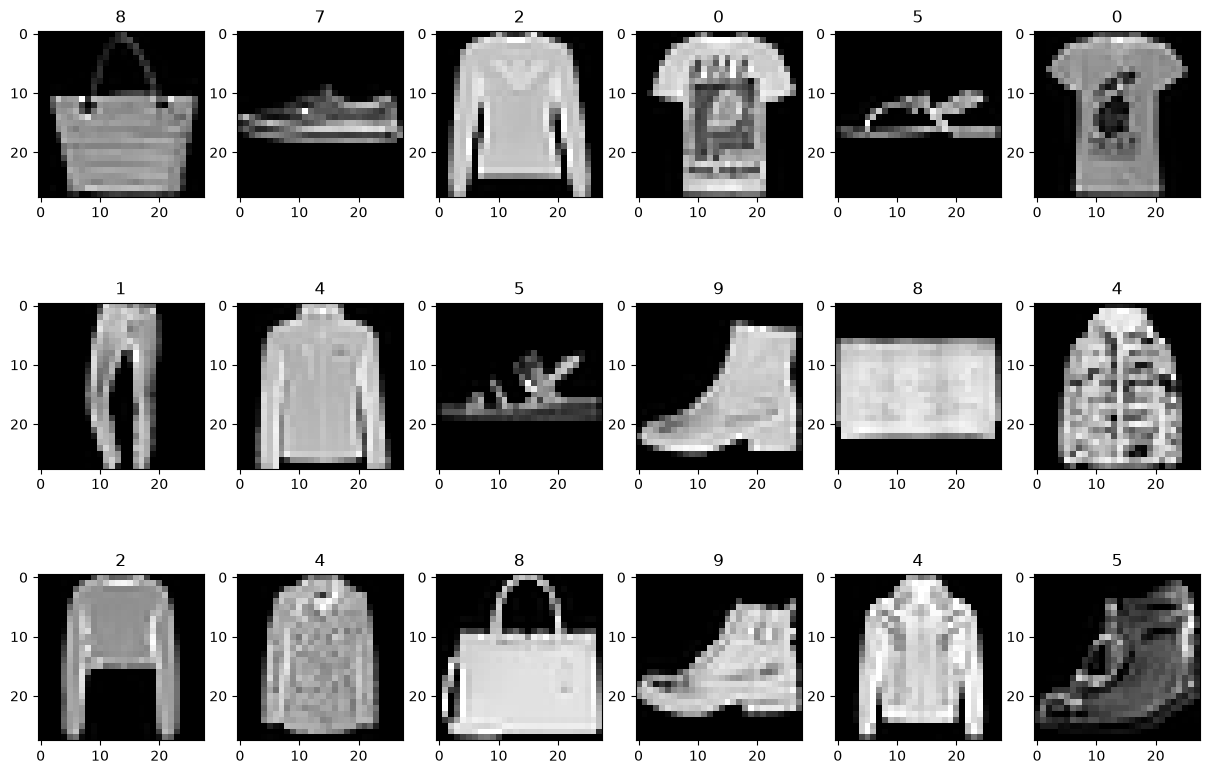

In [24]:
cnt = 1
for r in range(3):
    for c in range(6):
        idx = np.random.randint(len(x_train))
        plt.subplot(3,6,cnt)
        plt.imshow(x_train[idx, ...], cmap='gray')
        plt.title(y_train[idx])
        cnt = cnt + 1

### Building the Classifier

We are now going to build the baseline classifier that you will use throughout this homework.

In [25]:
# Data normalization
x_train = x_train/255
x_test = x_test/255

In [26]:
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same')(inputs)
net = Flatten()(net)
net = Dense(128)(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,213,002 (12.26 MB)

 Trainable params: 3,213,002 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
epochs = 50
batch_size = 64

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(x_test, y_test))

Epoch 1/50


I0000 00:00:1793623793.361446   29528 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_448182__.13


915/938 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8621 - loss: 0.3990

I0000 00:00:1793623795.891352   29524 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_448182__.13


938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8628 - loss: 0.3968 - val_accuracy: 0.8813 - val_loss: 0.3311
Epoch 2/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9060 - loss: 0.2634 - val_accuracy: 0.8908 - val_loss: 0.3084
Epoch 3/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9218 - loss: 0.2202 - val_accuracy: 0.8940 - val_loss: 0.3048
Epoch 4/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9327 - loss: 0.1903 - val_accuracy: 0.8939 - val_loss: 0.3151
Epoch 5/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9414 - loss: 0.1651 - val_accuracy: 0.8940 - val_loss: 0.3365
Epoch 6/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9491 - loss: 0.1457 - val_accuracy: 0.8933 - val_loss: 0.3544
Epoch 7/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9568 - loss: 0.1259 - val_accuracy: 0.8875 - val_loss: 0.3918
Epoch 8/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9616 - loss: 0.1119 - val_accuracy: 0.8871 - val_

Train Acc      0.9288166761398315
Validation Acc 0.8934999704360962


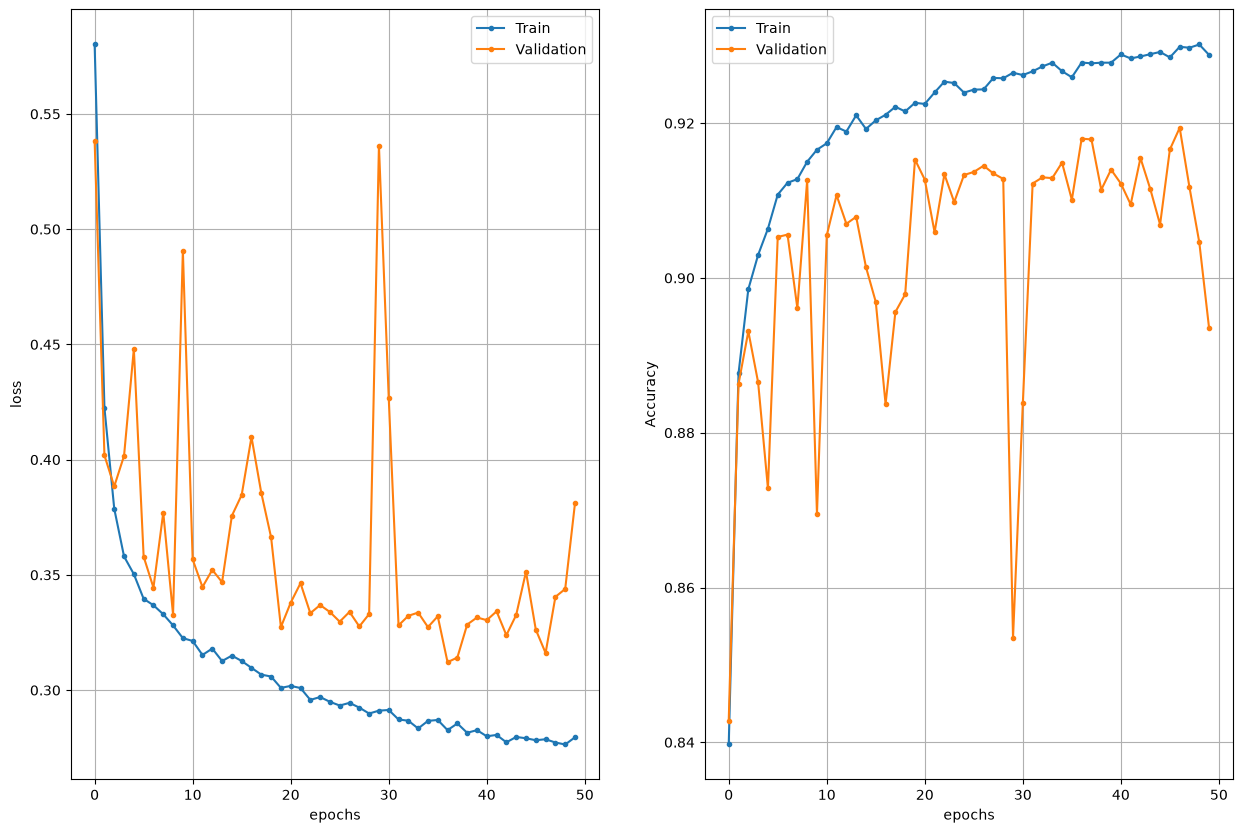

In [32]:
def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                               epochs, h['val_accuracy'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])
        
    print('Train Acc     ', h['accuracy'][-1])
    print('Validation Acc', h['val_accuracy'][-1])
    
plot_history(history)

As you can see, the classifier suffers from massive overfitting. The validation accuracy is around 88% while the training accuracy is close to 1.

### Combat the Overfitting!

Now it is your turn. Use the classifier as a baseline, include some regularization techniques and try to improve the classification performance. You can try any techniques you might see fit, e.g.,
* Dropout
* Batch normalization
* Weight regularization
* Data augmentation
* Early stopping
* Pooling
* Reducing the number of parameters (the size of the network)
* ...

There are to objective you shall fulfill in order to successfully complete this homework:
* The validation accuracy shall be above 91%
* Your network (with all the regularizations applied) shall **not** be larger than the baseline

In [89]:
# Modify the baseline classifier in order to reduce the overfitting and make the performance more robust
inputs = Input(shape=(28, 28, 1))

net = RandomFlip("horizontal")(inputs)
net = Conv2D(16, kernel_size=(3, 3), activation="relu", padding='same', kernel_regularizer=regularizers.l2(0.001))(inputs)
net = BatchNormalization()(net)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Dropout(0.15)(net)

net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same', kernel_regularizer=regularizers.l2(0.001))(net)
net = BatchNormalization()(net)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Dropout(0.15)(net)

net = Conv2D(64, kernel_size=(3, 3), activation="relu", padding='same', kernel_regularizer=regularizers.l2(0.001))(net)
net = BatchNormalization()(net)
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Dropout(0.2)(net)

net = Flatten()(net)
net = Dense(64)(net)
net = BatchNormalization()(net)
net = Dropout(0.4)(net)

outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_21 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_63          │ (None, 28, 28, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_64 (Dropout)            │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_64          │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_65 (Dropout)            │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_53 (Conv2D)              │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_65          │ (None, 7, 7, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_66 (Dropout)            │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_19 (Flatten)            │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_66          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_67 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,578 (240.54 KB)

 Trainable params: 61,226 (239.16 KB)

 Non-trainable params: 352 (1.38 KB)

In [92]:
# Train the network
epochs = 50
batch_size = 64

callbacks = [keras.callbacks.ModelCheckpoint("best_model.h5", save_best_only=True)]

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(x_test, y_test), callbacks=callbacks)

Epoch 1/50


I0000 00:00:1793628440.742531   29525 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2737613__.69


919/938 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8014 - loss: 0.6289

I0000 00:00:1793628445.600478   29527 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2737613__.69


938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8025 - loss: 0.6256

938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8025 - loss: 0.6256 - val_accuracy: 0.8639 - val_loss: 0.4351
Epoch 2/50
922/938 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8659 - loss: 0.4372

... (8 outputs left out)

938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9098 - loss: 0.3061 - val_accuracy: 0.9138 - val_loss: 0.2950
Epoch 18/50
920/938 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9103 - loss: 0.3055

938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9104 - loss: 0.3050 - val_accuracy: 0.9162 - val_loss: 0.2881
Epoch 19/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9111 - loss: 0.3050 - val_accuracy: 0.9153 - val_loss: 0.2902
Epoch 20/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9101 - loss: 0.3044 - val_accuracy: 0.9106 - val_loss: 0.3057
Epoch 21/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9102 - loss: 0.3040 - val_accuracy: 0.9109 - val_loss: 0.3000
Epoch 22/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9107 - loss: 0.3041 - val_accuracy: 0.9067 - val_loss: 0.3146
Epoch 23/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9118 - loss: 0.3000 - val_accuracy: 0.9137 - val_loss: 0.2955
Epoch 24/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9119 - loss: 0.2994 - val_accuracy: 0.9164 - val_loss: 0.2933
Epoch 25/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9110 - loss: 0.3003 - val_accuracy: 0.9139

938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9133 - loss: 0.2976 - val_accuracy: 0.9150 - val_loss: 0.2861
Epoch 28/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9140 - loss: 0.2977 - val_accuracy: 0.9135 - val_loss: 0.2916
Epoch 29/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9133 - loss: 0.2972 - val_accuracy: 0.9089 - val_loss: 0.3064
Epoch 30/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9135 - loss: 0.2963 - val_accuracy: 0.9157 - val_loss: 0.2974
Epoch 31/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9145 - loss: 0.2936 - val_accuracy: 0.9138 - val_loss: 0.2966
Epoch 32/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9147 - loss: 0.2948 - val_accuracy: 0.9135 - val_loss: 0.2983
Epoch 33/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9151 - loss: 0.2947 - val_accuracy: 0.9137 - val_loss: 0.3032
Epoch 34/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9156 - loss: 0.2934 - val_accuracy: 0.9135

938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9144 - loss: 0.2945 - val_accuracy: 0.9191 - val_loss: 0.2824
Epoch 36/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9150 - loss: 0.2921 - val_accuracy: 0.9170 - val_loss: 0.2902
Epoch 37/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9163 - loss: 0.2924 - val_accuracy: 0.9176 - val_loss: 0.2884
Epoch 38/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9150 - loss: 0.2932 - val_accuracy: 0.9137 - val_loss: 0.2965
Epoch 39/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9136 - loss: 0.2946 - val_accuracy: 0.9098 - val_loss: 0.3124
Epoch 40/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9164 - loss: 0.2907 - val_accuracy: 0.9192 - val_loss: 0.2825
Epoch 41/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9153 - loss: 0.2926 - val_accuracy: 0.8972 - val_loss: 0.3460
Epoch 42/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9156 - loss: 0.2906 - val_accuracy: 0.8916

Train Acc      0.9160333275794983
Validation Acc 0.9154000282287598
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


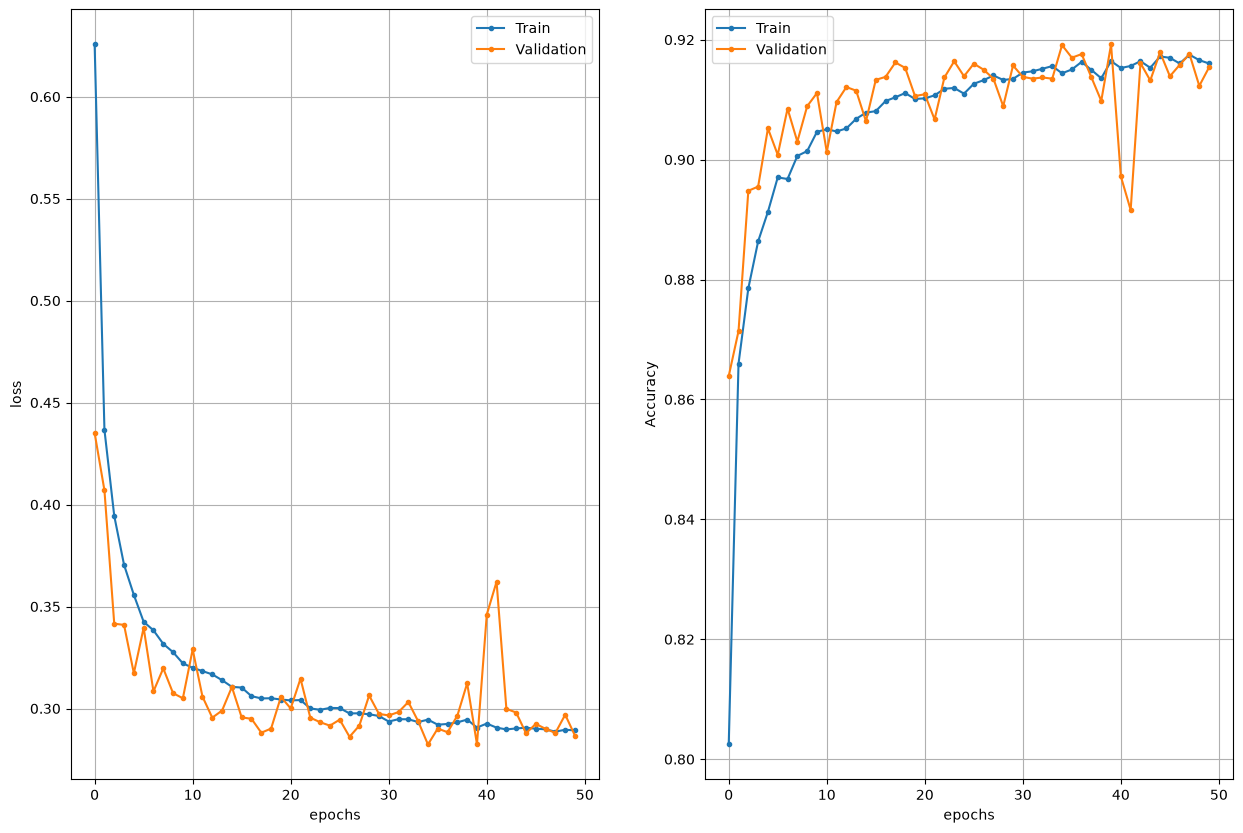

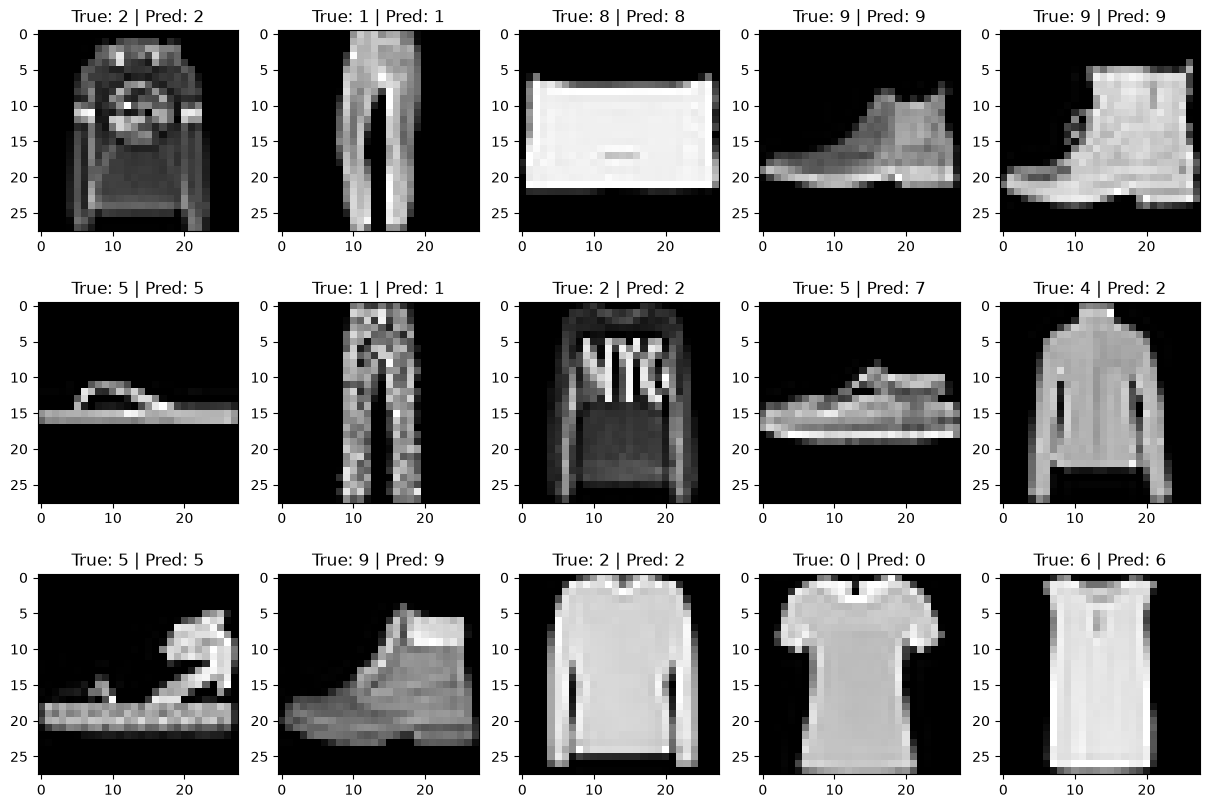

In [93]:
# Show the results
plot_history(history)

# Compute the labels and the predictions as sparse values
y_true = y_test
y_pred = np.argmax(model.predict(x_test), axis=1)

plt.figure()

for ii in range(15):
    # Pick a random sample
    idx = np.random.randint(0, len(y_pred))
    # Show the results
    plt.subplot(3,5,ii+1), plt.imshow(x_test[idx, ...], cmap='gray')
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

### Questions

* What have you done in order to improve the performance?

  So Basically to improve the performance the of the model I've tried different setups - added dropout, batch normalization, played around with reducing the number of the neurons for the layers, as well added data augmentation with a RandomFlip of the image, added regularizers and tried diffenet combinations, you can see them in the screenshots down below, so the accuracy in general went to 91%. And early stop as well to save the best model.

  

  1. Model 1

  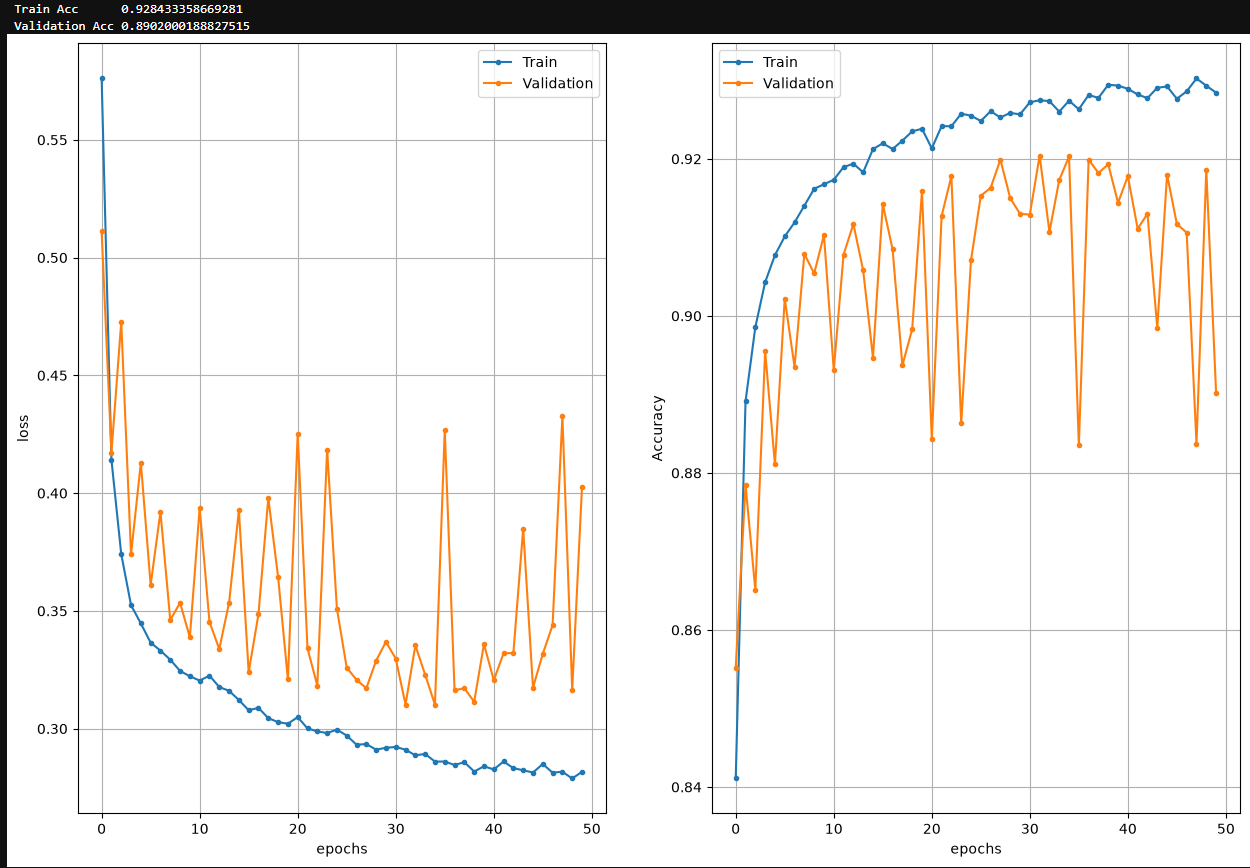

  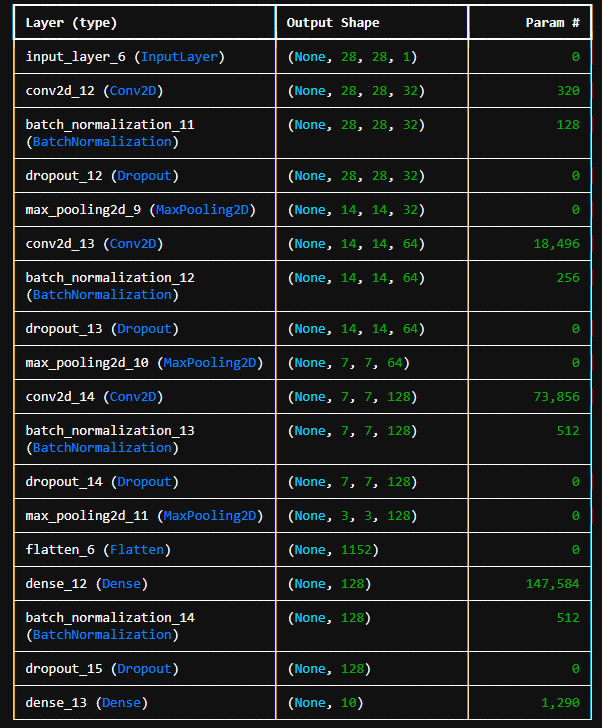

  2. Model 2

  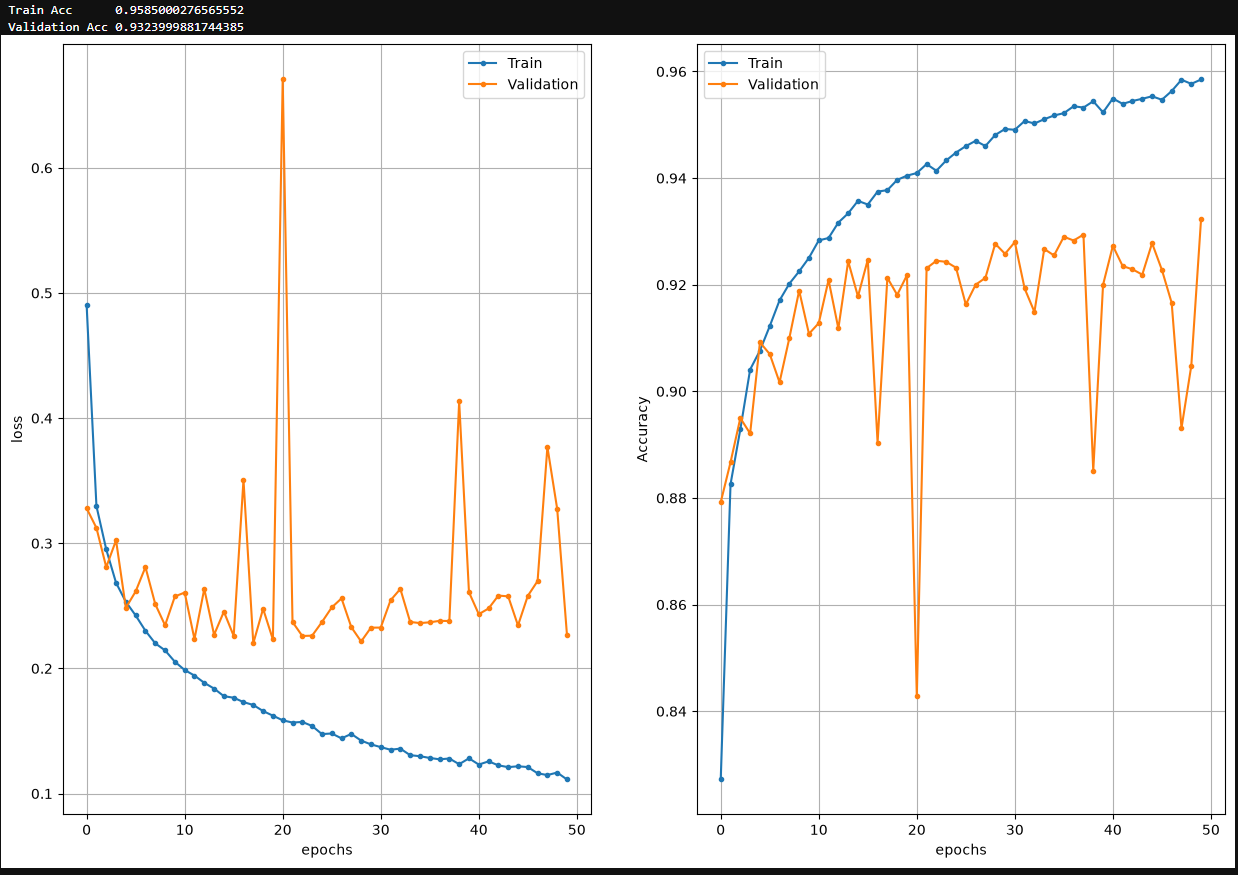


  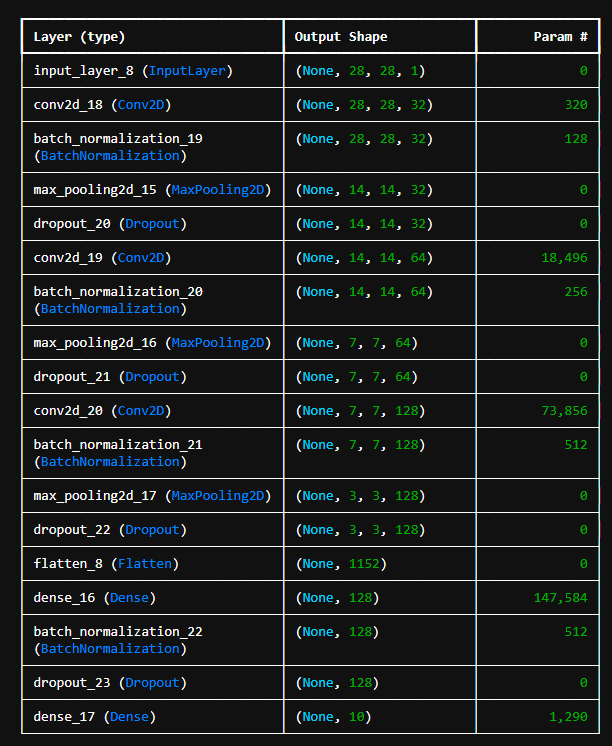


  3. Model 3

  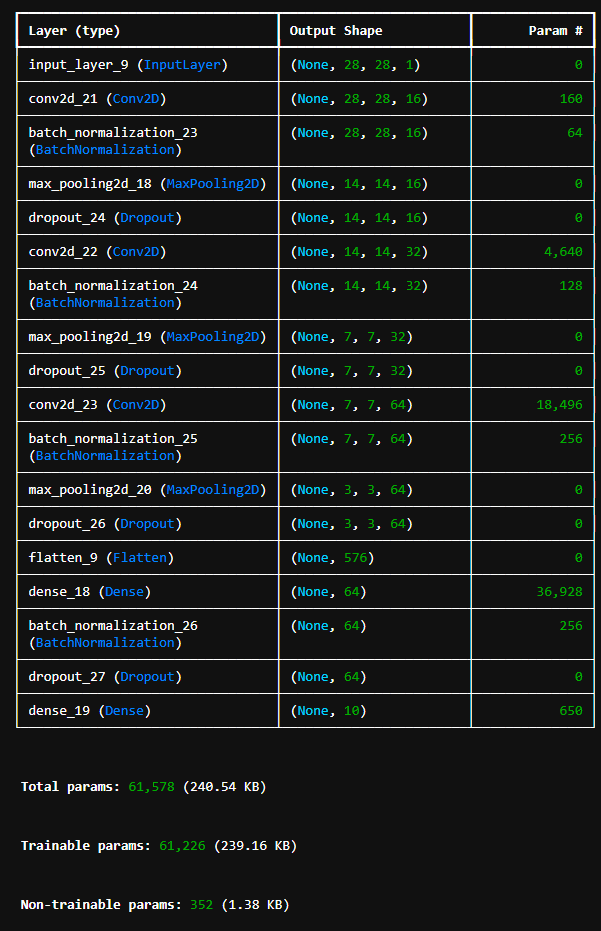

  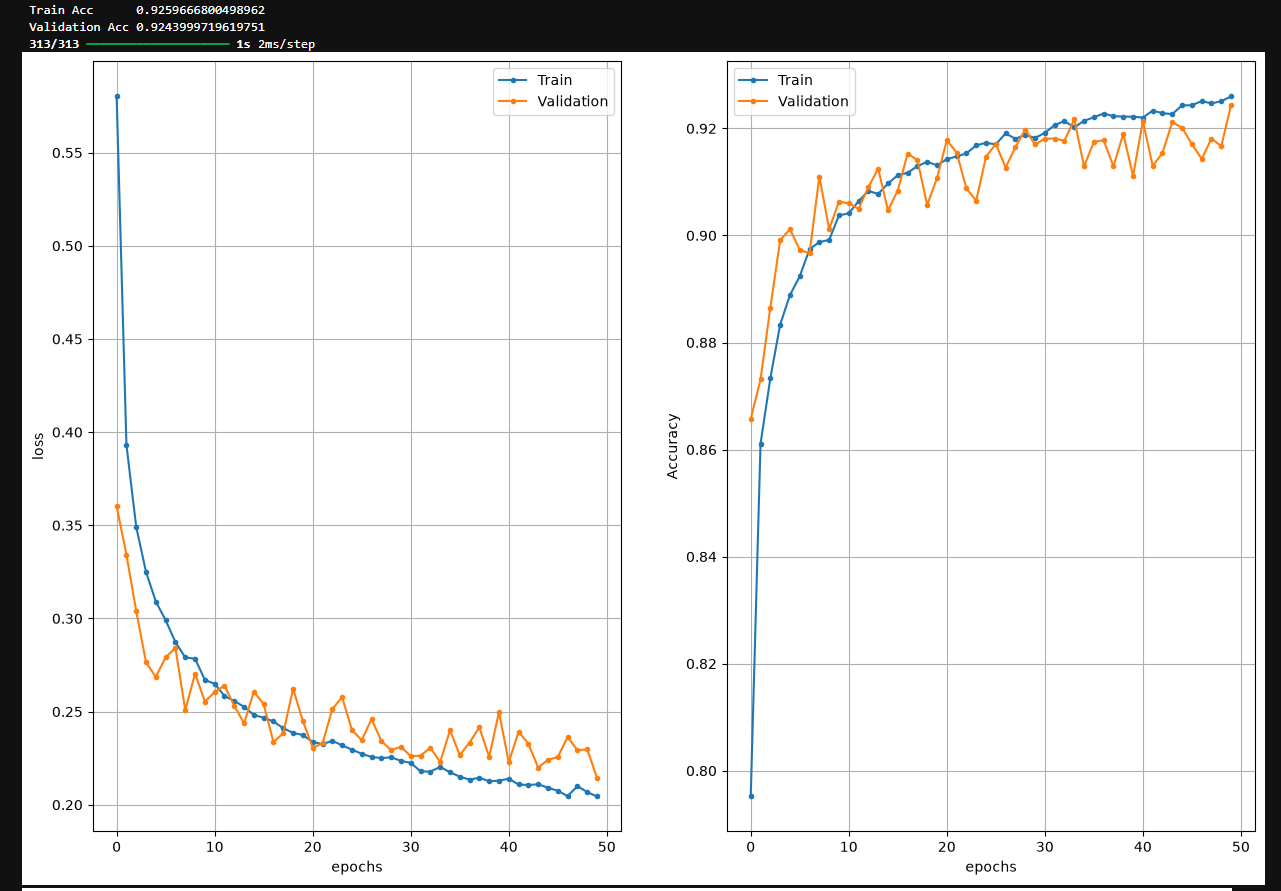


  4. Model 4
 
  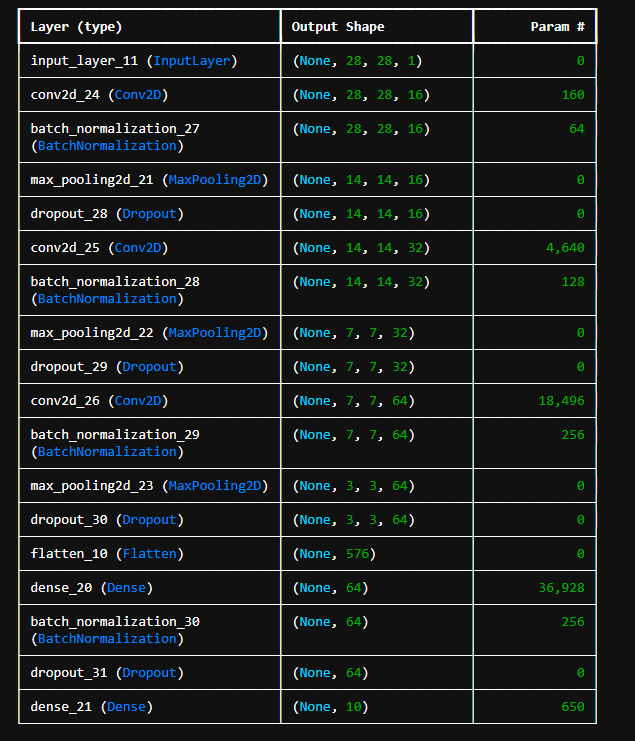

  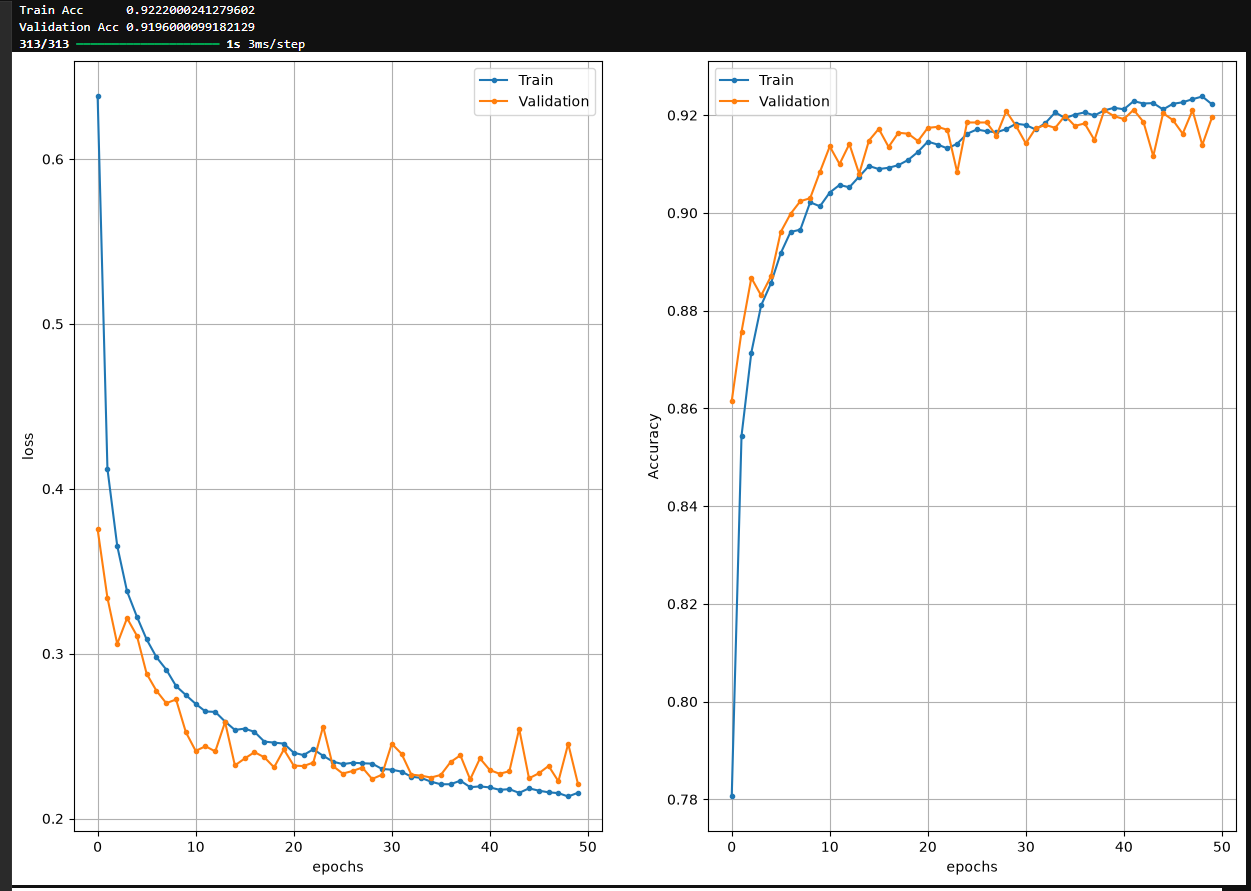


  5. Model 5
 
  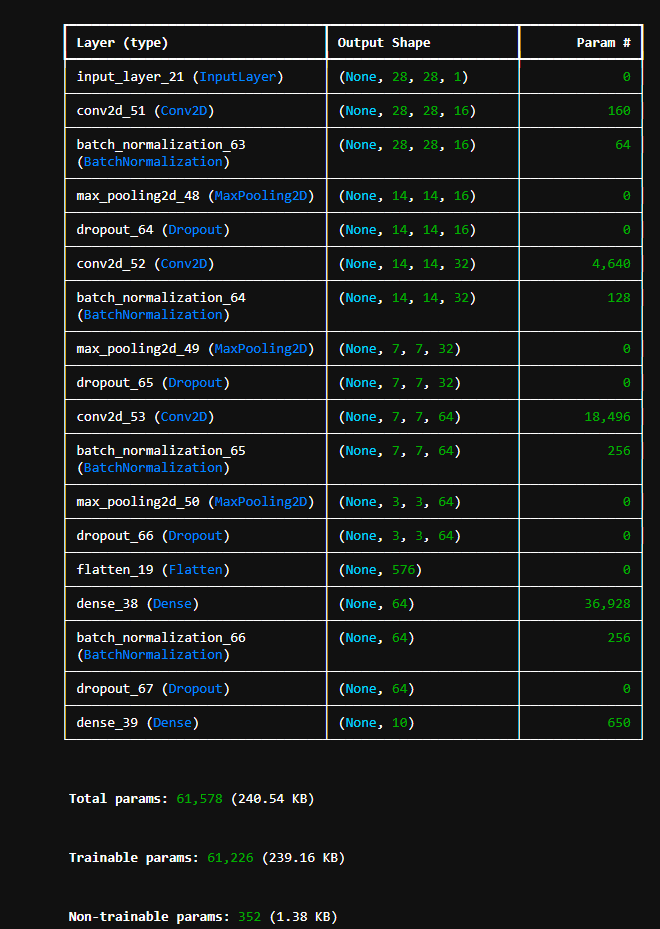
  
  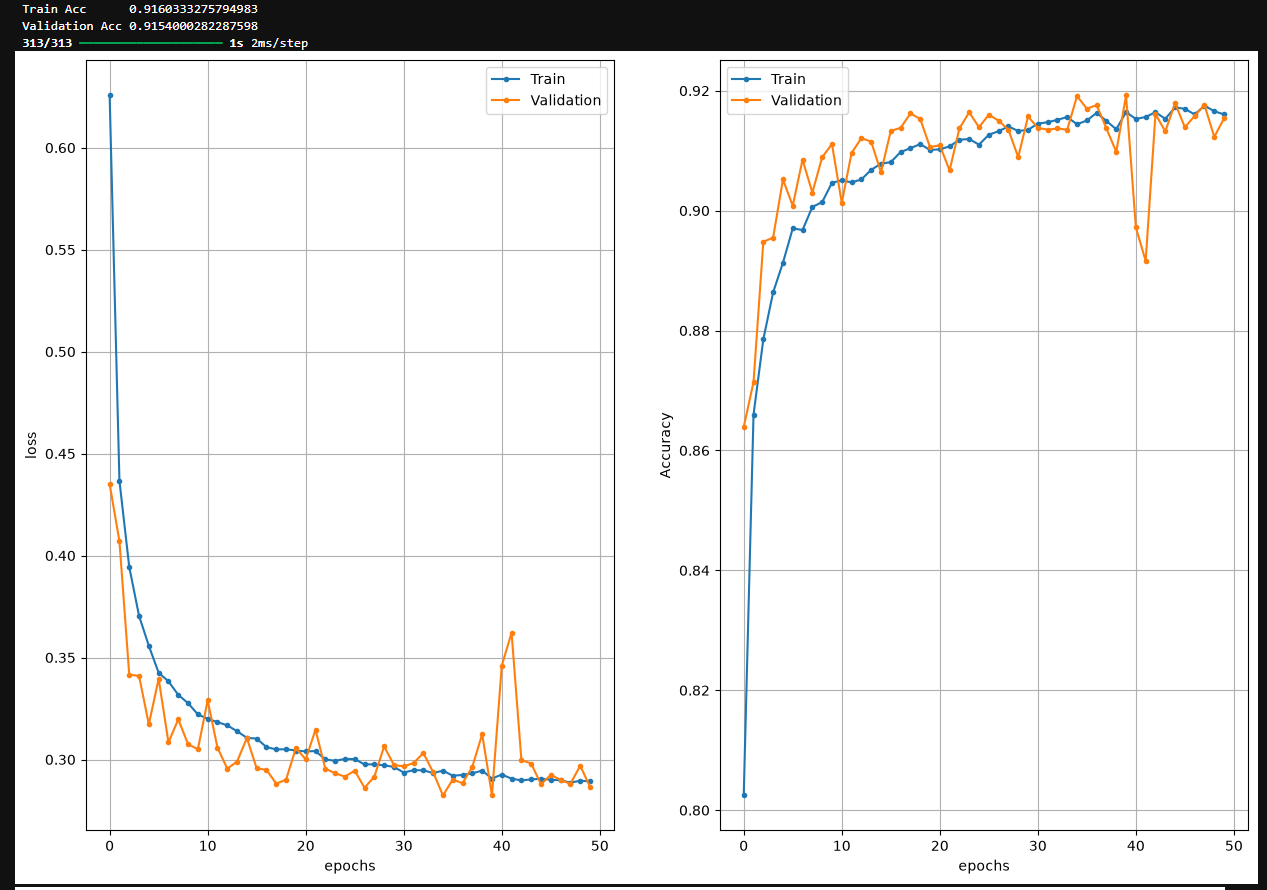
  
* Have you tried configurations that did not work out?

  As you can see there were Model 1 and Model 2 that were struggling during learning process and still have an example of overfitting To be honest, I've made so many changes across testing so reading the model summary does not tell me much at this moment what could affect those two models learning process. But as we discussed at the lecture, some things should be testested using empirical method so there were some results that show not succesfull attempts.